####  Actividad 3 CAMILO LOVERA - JUAN PABLO RODRÍGUEZ####

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# Ver 10 columnas
pd.set_option('display.max_columns', 10)

# Cargar datos
delitos = pd.read_csv("delitos_puerto_montt_2024 (1).csv", encoding="ISO-8859-1", sep=";", thousands=".")

# Renombrar columnas
delitos = delitos.rename(columns={'A¥O': 'AÑO'})
delitos['AÑO'] = delitos['AÑO'].ffill()
delitos.columns = delitos.columns.str.replace("??", " ", regex=False)
print(delitos.dtypes)

# Asegurar que AÑO y MES sean enteros
delitos['AÑO'] = delitos['AÑO'].astype(int)
delitos['MES'] = delitos['MES'].astype(int)

# Crear una columna de periodo YYYYMM para predecir secuencialmente
delitos['PERIODO'] = delitos['AÑO'] * 100 + delitos['MES']

print(delitos)


AÑO                                             float64
MES                                               int64
 Femicidio                                        int64
 Femicidio no ¡ntimo                              int64
 Suicidio femicida                                int64
 Violaci¢n con homicidio                          int64
 Robo con homicidio                               int64
 Auxilio al suicidio                              int64
 Otros homicidios                                 int64
 Tortura o apremios ileg¡timos con violaci¢n      int64
 Robo con violaci¢n                               int64
 Otras violaciones                                int64
 Abusos sexuales                                  int64
 Otros delitos sexuales                           int64
 Robos con violencia o intimidaci¢n               int64
 Robo violento de veh¡culo motorizado             int64
 Violencia intrafamiliar a mujer                  int64
 Violencia intrafamiliar a ni¤o o ni¤a          

In [3]:
# Periodo
X = delitos[['PERIODO']]

# Todas las columnas de delitos, excepto AÑO, MES, PERIODO
y = delitos.drop(columns=['AÑO', 'MES', 'PERIODO'])

# Dividir en entrenamiento y testeo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Testeo:", X_test.shape, y_test.shape)


Entrenamiento: (192, 1) (192, 37)
Testeo: (48, 1) (48, 37)


In [4]:
# Random Forest Regressor para cada delito
modelo = RandomForestRegressor(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [5]:
# Evaluación del Entrenamiento con el modelo
from sklearn.metrics import mean_squared_error, r2_score

y_predicted = modelo.predict(X_train)
rmse = np.sqrt(mean_squared_error(y_train, y_predicted))
r2 = r2_score(y_train, y_predicted)

print("Rendimiento del conjunto de Entrenamiento")
print("RMSE: {}".format(rmse))
print("R2: {}".format(r2))

Rendimiento del conjunto de Entrenamiento
RMSE: 15.582104823726883
R2: 0.9109794493834008


In [6]:
# Estimación del siguiente período
proximo_periodo = pd.DataFrame(
    [[delitos['PERIODO'].max() + 1]],
    columns=X_train.columns
)

# Hacer predicción
prediccion = modelo.predict(proximo_periodo)
pred = pd.DataFrame(prediccion, columns=y.columns, index=['Predicción'])
print(pred.T.sort_values(by='Predicción', ascending=False).head(40))

                                             Predicción
Otros delitos o faltas                          3555.66
Violencia intrafamiliar a mujer                  602.92
Robos en lugar no habitado                       175.18
Robo en lugar habitado                           143.22
Violencia intrafamiliar a hombre                 140.72
Robo de objetos de o desde veh¡culo              128.62
Otras infracciones a la ley de armas             126.28
Robos con violencia o intimidaci¢n                94.26
Comercio ilegal                                   64.98
Animales sueltos en la v¡a p£blica                62.94
Otras incivilidades                               62.52
Abusos sexuales                                   55.38
Ofensas al pudor                                  42.32
Microtr fico de sustancias                        36.76
Violencia intrafamiliar no clasificada            33.94
Abigeato                                          31.44
Otros delitos sexuales                          

In [7]:
top_5 = pred.T.sort_values(by='Predicción', ascending=False).head(5)
print("Top 5 delitos con mayor predicción para el siguiente período:")
print(top_5)


Top 5 delitos con mayor predicción para el siguiente período:
                                  Predicción
Otros delitos o faltas               3555.66
Violencia intrafamiliar a mujer       602.92
Robos en lugar no habitado            175.18
Robo en lugar habitado                143.22
Violencia intrafamiliar a hombre      140.72


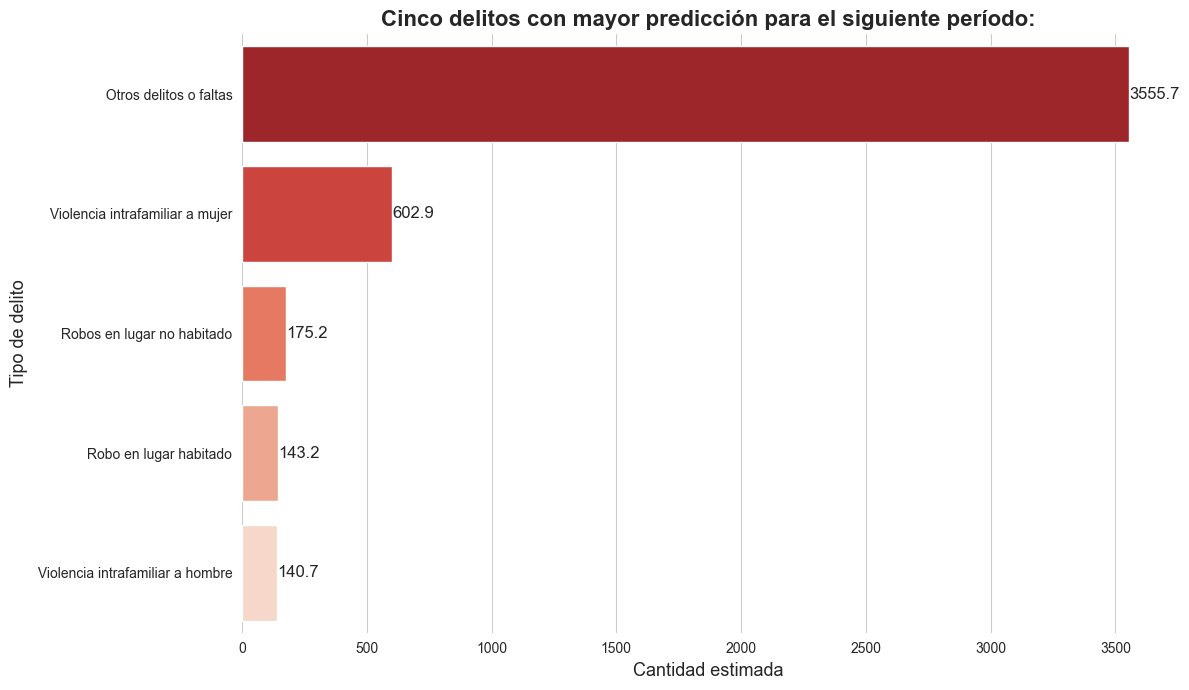

In [8]:
# DataFrame con un índice como columna para usarlo como hue
top_5_reset = top_5.reset_index().rename(columns={'index': 'Delito'})

plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Creamos el gráfico
ax = sns.barplot(
    data=top_5_reset,
    x='Predicción',
    y='Delito',
    hue='Delito',
    dodge=False,
    palette="Reds_r",
    legend=False  
)

# Título y ejes
plt.title("Cinco delitos con mayor predicción para el siguiente período:", fontsize=16, weight='bold')
plt.xlabel("Cantidad estimada", fontsize=13)
plt.ylabel("Tipo de delito", fontsize=13)

# Mostrar los valores sobre cada barra
for i, row in top_5_reset.iterrows():
    ax.text(row['Predicción'] + 1, i, f"{row['Predicción']:.1f}", va='center', fontsize=12)


sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()
